--> Procesando: Las pintas 2023.xlsx...
--> Procesando: Las pintas 2024.xlsx...

¡Procesamiento horario finalizado con éxito!
Total registros cargados: 17544 (2023: 8760, 2024: 8784)
¡Reporte Excel generado y estilizado exitosamente!: 'Resultados_Aire_y_Salud_LasPintas_2023_2024.xlsx'


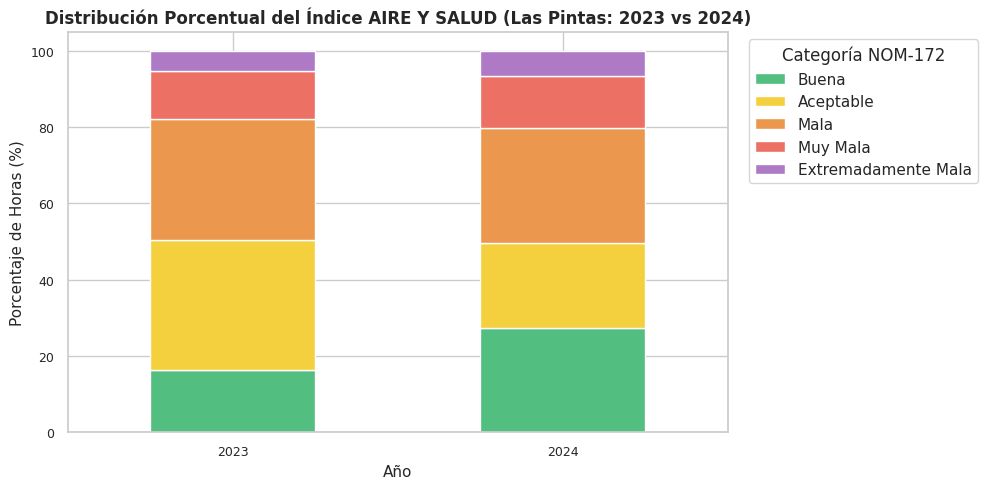

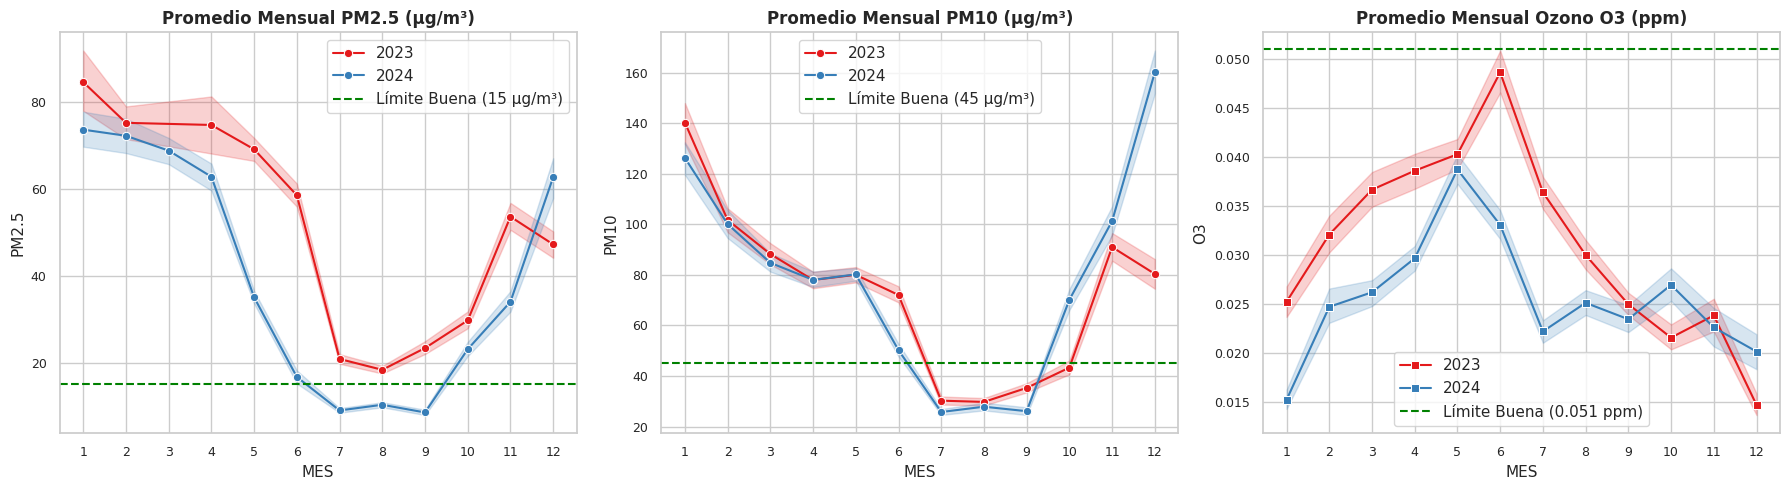

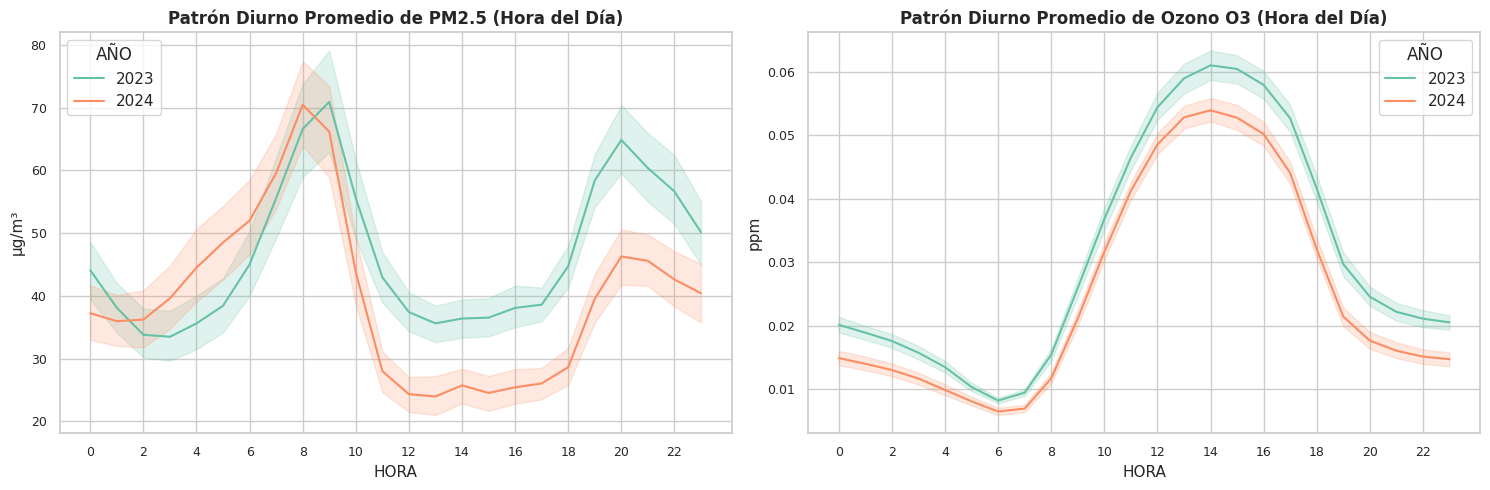

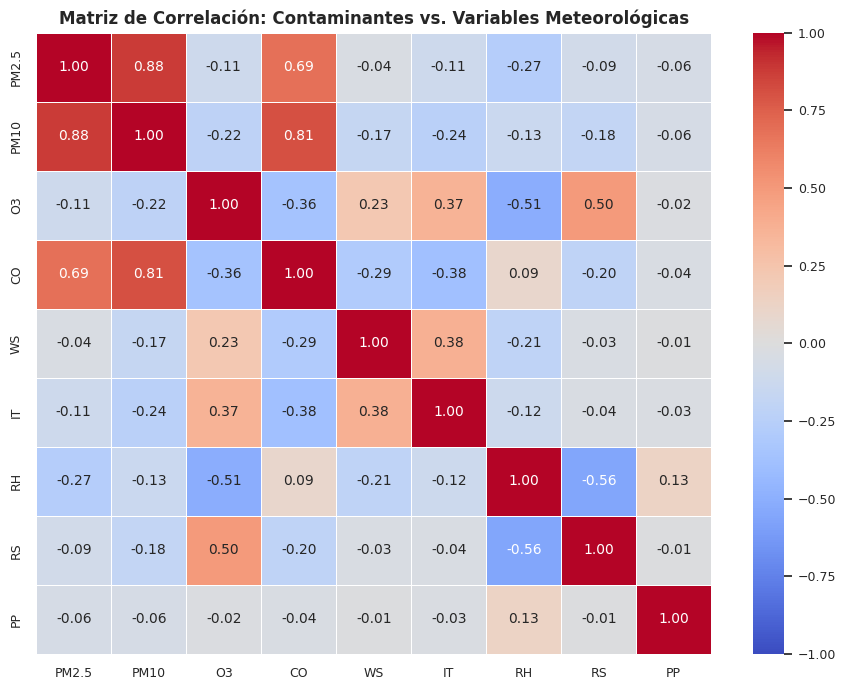


RESUMEN DE RESULTADOS: COMPARATIVA 2023 VS 2024 (ESTACIÓN LAS PINTAS)
       PM2.5    PM10     O3     CO     WS      IT      RH
AÑO                                                      
2023  46.865  73.074  0.031  0.740  3.046  21.106  38.149
2024  40.333  78.346  0.026  0.907  2.261  20.948  59.380


In [ ]:
# PIPELINE COMPLETO DE ANÁLISIS DE CALIDAD DEL AIRE Y METEOROLOGÍA (NOM-172)
# Estación: Las Pintas (PIN) | Comparativa 2023 vs 2024

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from decimal import Decimal, ROUND_HALF_UP

# Set de estilo visual para gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 14
})

# NORMATIVAS (NOM-172-SEMARNAT-2023)

def redondear_nom(v, decimales=0):
    """ Redondeo aritmético estándar (Round Half Up) normativo. """
    if pd.isna(v) or v is None:
        return np.nan
    try:
        d = Decimal(str(float(v)))
        if decimales == 0:
            return int(d.quantize(Decimal('1'), rounding=ROUND_HALF_UP))
        else:
            fmt = '0.' + '0' * decimales
            return float(d.quantize(Decimal(fmt), rounding=ROUND_HALF_UP))
    except Exception:
        return np.nan

def calcular_nowcast_serie(series):
    """
    Calcula el indicador NowCast hora a hora para partículas (PM10 / PM2.5)
    basado en la ventana ponderada de 12 horas.
    """
    nowcasts = []
    for i in range(len(series)):
        ventana = series.iloc[max(0, i - 11):i + 1].dropna()
        if len(ventana) < 2:
            nowcasts.append(np.nan)
            continue
        c_max = ventana.max()
        c_min = ventana.min()
        w = 1 - (c_max - c_min) / c_max if c_max > 0 else 1.0
        w = max(w, 0.5)

        pesos = [w**(len(ventana) - 1 - idx) for idx in range(len(ventana))]
        nowcasts.append((ventana * pesos).sum() / sum(pesos))
    return pd.Series(nowcasts, index=series.index)

# Funciones de Categorización (NOM-172-SEMARNAT-2023)
def cat_pm25(v):
    if pd.isna(v): return np.nan
    if v <= 15.0: return 'Buena'
    elif v <= 41.0: return 'Aceptable'
    elif v <= 79.0: return 'Mala'
    elif v <= 130.0: return 'Muy Mala'
    else: return 'Extremadamente Mala'

def cat_pm10(v):
    if pd.isna(v): return np.nan
    if v <= 45.0: return 'Buena'
    elif v <= 70.0: return 'Aceptable'
    elif v <= 132.0: return 'Mala'
    elif v <= 213.0: return 'Muy Mala'
    else: return 'Extremadamente Mala'

def cat_o3_1h(v):
    if pd.isna(v): return np.nan
    if v <= 0.051: return 'Buena'
    elif v <= 0.070: return 'Aceptable'
    elif v <= 0.092: return 'Mala'
    elif v <= 0.114: return 'Muy Mala'
    else: return 'Extremadamente Mala'

def cat_co(v):
    if pd.isna(v): return np.nan
    if v <= 5.0: return 'Buena'
    elif v <= 9.5: return 'Aceptable'
    elif v <= 11.5: return 'Mala'
    elif v <= 13.5: return 'Muy Mala'
    else: return 'Extremadamente Mala'

def cat_no2(v):
    if pd.isna(v): return np.nan
    if v <= 0.107: return 'Buena'
    elif v <= 0.210: return 'Aceptable'
    elif v <= 0.230: return 'Mala'
    elif v <= 0.250: return 'Muy Mala'
    else: return 'Extremadamente Mala'

def cat_so2(v):
    if pd.isna(v): return np.nan
    if v <= 0.035: return 'Buena'
    elif v <= 0.075: return 'Aceptable'
    elif v <= 0.185: return 'Mala'
    elif v <= 0.304: return 'Muy Mala'
    else: return 'Extremadamente Mala'

sev_map = {'Buena': 1, 'Aceptable': 2, 'Mala': 3, 'Muy Mala': 4, 'Extremadamente Mala': 5}
inv_sev_map = {1: 'Buena', 2: 'Aceptable', 3: 'Mala', 4: 'Muy Mala', 5: 'Extremadamente Mala'}

# PROCESAMIENTO Y LIMPIEZA DE DATOS HORARIOS

def procesar_archivo_ano(ruta_archivo, anio_predeterminado):
    print(f"--> Procesando: {ruta_archivo}...")
    xls = pd.ExcelFile(ruta_archivo)
    sheet_name = 'Data' if 'Data' in xls.sheet_names else xls.sheet_names[0]
    df = pd.read_excel(ruta_archivo, sheet_name=sheet_name)

    df.columns = [str(c).strip().upper() for c in df.columns]

    df['DATETIME'] = pd.to_datetime(df['DATE'], errors='coerce')
    df['AÑO'] = df['DATETIME'].dt.year.fillna(anio_predeterminado).astype(int)
    df['MES'] = df['DATETIME'].dt.month
    df['DIA'] = df['DATETIME'].dt.date
    df['HORA'] = df['HOUR'] if 'HOUR' in df.columns else df['DATETIME'].dt.hour

    cols_numericas = ['PM10', 'PM2.5', 'O3', 'CO', 'NO', 'NO2', 'NOX', 'SO2',
                      'WS', 'WD', 'IT', 'ET', 'RH', 'RS', 'PP', 'ATM', 'UVI']
    for c in cols_numericas:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')

    if 'O3' in df.columns and not df['O3'].dropna().empty:
        if df['O3'].dropna().median() > 1.0:
            print(f"    Nota: Se detectó O3 en ppb en {ruta_archivo}. Convirtiendo a ppm...")
            df['O3'] = df['O3'] / 1000.0

    # Cálculo de Promedios Móviles y NowCast
    if 'PM10' in df.columns:
        df['PM10_24H'] = df['PM10'].rolling(24, min_periods=18).mean()
        df['PM10_NOWCAST'] = calcular_nowcast_serie(df['PM10'])
        df['IAS_PM10_CAT'] = df['PM10_NOWCAST'].apply(cat_pm10)
    else:
        df['PM10_24H'], df['PM10_NOWCAST'], df['IAS_PM10_CAT'] = np.nan, np.nan, np.nan

    if 'PM2.5' in df.columns:
        df['PM2.5_24H'] = df['PM2.5'].rolling(24, min_periods=18).mean()
        df['PM2.5_NOWCAST'] = calcular_nowcast_serie(df['PM2.5'])
        df['IAS_PM2.5_CAT'] = df['PM2.5_NOWCAST'].apply(cat_pm25)
    else:
        df['PM2.5_24H'], df['PM2.5_NOWCAST'], df['IAS_PM2.5_CAT'] = np.nan, np.nan, np.nan

    if 'O3' in df.columns:
        df['O3_8H'] = df['O3'].rolling(8, min_periods=6).mean()
        df['IAS_O3_CAT'] = df['O3'].apply(cat_o3_1h)
    else:
        df['O3_8H'], df['IAS_O3_CAT'] = np.nan, np.nan

    if 'CO' in df.columns:
        df['CO_8H'] = df['CO'].rolling(8, min_periods=6).mean()
        df['IAS_CO_CAT'] = df['CO_8H'].apply(cat_co)
    else:
        df['CO_8H'], df['IAS_CO_CAT'] = np.nan, np.nan

    df['IAS_NO2_CAT'] = df['NO2'].apply(cat_no2) if 'NO2' in df.columns else np.nan
    df['IAS_SO2_CAT'] = df['SO2'].apply(cat_so2) if 'SO2' in df.columns else np.nan

    # Categoría Global e Identificación de Poluyente Determinante
    def obtener_categoria_global(row):
        cats = {
            'PM10': row.get('IAS_PM10_CAT'),
            'PM2.5': row.get('IAS_PM2.5_CAT'),
            'O3': row.get('IAS_O3_CAT'),
            'CO': row.get('IAS_CO_CAT'),
            'NO2': row.get('IAS_NO2_CAT'),
            'SO2': row.get('IAS_SO2_CAT')
        }
        validos = {p: c for p, c in cats.items() if pd.notna(c) and c in sev_map}
        if not validos:
            return np.nan, np.nan
        max_score = max(sev_map[c] for c in validos.values())
        peores_pols = [p for p, c in validos.items() if sev_map[c] == max_score]
        return inv_sev_map[max_score], ", ".join(peores_pols)

    res_global = df.apply(obtener_categoria_global, axis=1)
    df['IAS_GLOBAL_CAT'] = [r[0] for r in res_global]
    df['IAS_GLOBAL_POL'] = [r[1] for r in res_global]

    return df

archivos_2023 = glob.glob('*2023*.xlsx')
archivos_2024 = glob.glob('*2024*.xlsx')

ruta_2023 = [f for f in archivos_2023 if os.path.getsize(f) > 50000][0] if [f for f in archivos_2023 if os.path.getsize(f) > 50000] else 'Las pintas 2023.xlsx'
ruta_2024 = archivos_2024[0] if archivos_2024 else 'Las pintas 2024.xlsx'

df_2023 = procesar_archivo_ano(ruta_2023, 2023)
df_2024 = procesar_archivo_ano(ruta_2024, 2024)
df_total = pd.concat([df_2023, df_2024], ignore_index=True)

print("\n¡Procesamiento horario finalizado con éxito!")
print(f"Total registros cargados: {len(df_total)} (2023: {len(df_2023)}, 2024: {len(df_2024)})")

# AGREGACIÓN DIARIA CON VALIDACIÓN DE SUFICIENCIA (75% / 18 HORAS)

def generar_resumen_diario(df):
    filas_diarias = []
    for (anio, dia), group in df.groupby(['AÑO', 'DIA']):
        row = {'AÑO': anio, 'DATE': dia}
        cats_dia = {}

        for pol in ['PM2.5', 'PM10', 'O3']:
            if pol in group.columns:
                validos = group[pol].dropna()
                n_val = len(validos)
                cumple = n_val >= 18
                row[f'Validos_{pol}'] = n_val
                row[f'Suficiencia_{pol}'] = 'Cumple' if cumple else 'No cumple'

                if pol == 'O3':
                    row[f'{pol}_AVG_24H'] = redondear_nom(validos.mean(), 3) if cumple else np.nan
                    row[f'{pol}_MAX_1H'] = redondear_nom(validos.max(), 3) if n_val > 0 else np.nan
                    c_val = cat_o3_1h(row[f'{pol}_MAX_1H'])
                elif pol == 'PM2.5':
                    row[f'{pol}_AVG_24H'] = redondear_nom(validos.mean(), 0) if cumple else np.nan
                    row[f'{pol}_MAX_1H'] = redondear_nom(validos.max(), 0) if n_val > 0 else np.nan
                    c_val = cat_pm25(row[f'{pol}_AVG_24H'])
                elif pol == 'PM10':
                    row[f'{pol}_AVG_24H'] = redondear_nom(validos.mean(), 0) if cumple else np.nan
                    row[f'{pol}_MAX_1H'] = redondear_nom(validos.max(), 0) if n_val > 0 else np.nan
                    c_val = cat_pm10(row[f'{pol}_AVG_24H'])

                row[f'Cat_{pol}'] = c_val
                if pd.notna(c_val):
                    cats_dia[pol] = c_val

        # Categoría Global Diaria de la Estación
        if cats_dia:
            max_s = max(sev_map[c] for c in cats_dia.values())
            row['Cat_Global_Estacion'] = inv_sev_map[max_s]
            row['Contaminante_Determinante'] = ", ".join([p for p, c in cats_dia.items() if sev_map[c] == max_s])
        else:
            row['Cat_Global_Estacion'] = np.nan
            row['Contaminante_Determinante'] = 'N/A'

        filas_diarias.append(row)
    return pd.DataFrame(filas_diarias)

df_diario = generar_resumen_diario(df_total)

# EXPORTACIÓN A EXCEL

archivo_salida_excel = 'Resultados_Aire_y_Salud_LasPintas_2023_2024.xlsx'
with pd.ExcelWriter(archivo_salida_excel, engine='openpyxl') as writer:
    df_total.to_excel(writer, sheet_name='Datos_Horarios', index=False)
    df_diario.to_excel(writer, sheet_name='Calculos_Diarios', index=False)

wb = openpyxl.load_workbook(archivo_salida_excel)
font_header = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
fill_header = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid')
font_data = Font(name='Segoe UI', size=10)
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

category_colors = {
    'Buena': {'fill': 'C6EFCE', 'font': '006100'},
    'Aceptable': {'fill': 'FFEB9C', 'font': '9C6500'},
    'Mala': {'fill': 'FCE4D6', 'font': 'C65911'},
    'Muy Mala': {'fill': 'FFC7CE', 'font': '9C0006'},
    'Extremadamente Mala': {'fill': 'E1D5E7', 'font': '622383'}
}

for sheetname in wb.sheetnames:
    ws = wb[sheetname]
    ws.freeze_panes = 'B2'
    ws.row_dimensions[1].height = 28

    for col_num in range(1, ws.max_column + 1):
        cell = ws.cell(row=1, column=col_num)
        cell.font = font_header
        cell.fill = fill_header
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)

    for row in ws.iter_rows(min_row=2, max_row=ws.max_row, min_col=1, max_col=ws.max_column):
        for cell in row:
            cell.font = font_data
            cell.border = thin_border
            val_str = str(cell.value) if cell.value is not None else ''

            if val_str in category_colors:
                cell.fill = PatternFill(start_color=category_colors[val_str]['fill'], fill_type='solid')
                cell.font = Font(name='Segoe UI', size=10, bold=True, color=category_colors[val_str]['font'])
                cell.alignment = Alignment(horizontal='center')

    for col in ws.columns:
        max_len = max(len(str(cell.value or '')) for cell in col)
        letra = get_column_letter(col[0].column)
        ws.column_dimensions[letra].width = min(max(max_len + 3, 12), 26)

wb.save(archivo_salida_excel)
print(f"¡Reporte Excel generado y estilizado exitosamente!: '{archivo_salida_excel}'")

# GENERACIÓN DE GRÁFICOS ANALÍTICOS Y VISUALIZACIONES
# Gráfico 1: Comparativa Porcentual del Índice AIRE Y SALUD (2023 vs 2024)
fig, ax = plt.subplots(figsize=(10, 5))
comp_anual = df_total.groupby('AÑO')['IAS_GLOBAL_CAT'].value_counts(normalize=True).unstack() * 100
orden_cats = ['Buena', 'Aceptable', 'Mala', 'Muy Mala', 'Extremadamente Mala']
cols_presentes = [c for c in orden_cats if c in comp_anual.columns]
comp_anual[cols_presentes].plot(kind='bar', stacked=True, ax=ax,
                                 color=['#52BE80', '#F4D03F', '#EB984E', '#EC7063', '#AF7AC5'])
ax.set_title('Distribución Porcentual del Índice AIRE Y SALUD (Las Pintas: 2023 vs 2024)', fontweight='bold')
ax.set_ylabel('Porcentaje de Horas (%)')
ax.set_xlabel('Año')
plt.xticks(rotation=0)
plt.legend(title='Categoría NOM-172', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Gráfico 2: Comportamiento Mensual (PM2.5, PM10, O3)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=df_total, x='MES', y='PM2.5', hue='AÑO', marker='o', ax=axes[0], palette='Set1')
axes[0].set_title('Promedio Mensual PM2.5 (µg/m³)', fontweight='bold')
axes[0].axhline(15, color='green', linestyle='--', label='Límite Buena (15 µg/m³)')
axes[0].set_xticks(range(1, 13))
axes[0].legend()

sns.lineplot(data=df_total, x='MES', y='PM10', hue='AÑO', marker='o', ax=axes[1], palette='Set1')
axes[1].set_title('Promedio Mensual PM10 (µg/m³)', fontweight='bold')
axes[1].axhline(45, color='green', linestyle='--', label='Límite Buena (45 µg/m³)')
axes[1].set_xticks(range(1, 13))
axes[1].legend()

sns.lineplot(data=df_total, x='MES', y='O3', hue='AÑO', marker='s', ax=axes[2], palette='Set1')
axes[2].set_title('Promedio Mensual Ozono O3 (ppm)', fontweight='bold')
axes[2].axhline(0.051, color='green', linestyle='--', label='Límite Buena (0.051 ppm)')
axes[2].set_xticks(range(1, 13))
axes[2].legend()

plt.tight_layout()
plt.show()

# Gráfico 3: Ciclo Diurno Promedio por Hora
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(data=df_total, x='HORA', y='PM2.5', hue='AÑO', ax=axes[0], palette='Set2')
axes[0].set_title('Patrón Diurno Promedio de PM2.5 (Hora del Día)', fontweight='bold')
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_ylabel('µg/m³')

sns.lineplot(data=df_total, x='HORA', y='O3', hue='AÑO', ax=axes[1], palette='Set2')
axes[1].set_title('Patrón Diurno Promedio de Ozono O3 (Hora del Día)', fontweight='bold')
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_ylabel('ppm')

plt.tight_layout()
plt.show()

# Gráfico 4: Matriz de Correlación Meteorológica
vars_met = ['PM2.5', 'PM10', 'O3', 'CO', 'WS', 'IT', 'RH', 'RS', 'PP']
cols_corr = [c for c in vars_met if c in df_total.columns]

plt.figure(figsize=(9, 7))
corr_mat = df_total[cols_corr].corr()
sns.heatmap(corr_mat, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación: Contaminantes vs. Variables Meteorológicas', fontweight='bold')
plt.tight_layout()
plt.show()

# TABLA RESUMEN DE HALLAZGOS INTERANUALES

print("\n" + "="*80)
print("RESUMEN DE RESULTADOS: COMPARATIVA 2023 VS 2024 (ESTACIÓN LAS PINTAS)")
print("="*80)
tabla_resumen = df_total.groupby('AÑO')[['PM2.5', 'PM10', 'O3', 'CO', 'WS', 'IT', 'RH']].mean()
print(tabla_resumen.round(3))
print("="*80)